In [ ]:
!pip install -q huggingface_hub pycocotools opencv-python pandas matplotlib seaborn

In [ ]:
from huggingface_hub import HfApi, hf_hub_download
import os
import json

REPO_ID = "iisc-aim/UVH-26"

# List files available in the public dataset
api = HfApi()

repo_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

# Find the validation annotation file
annotation_matches = [
    f for f in repo_files
    if f.endswith("UVH-26-MV-Val.json")
]

if not annotation_matches:
    raise FileNotFoundError("Validation annotation JSON not found.")

ANNOTATION_FILE = annotation_matches[0]

print("Annotation file:", ANNOTATION_FILE)

# Download only the JSON annotation file
annotation_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=ANNOTATION_FILE,
    repo_type="dataset"
)

# Load COCO annotations
with open(annotation_path, "r") as f:
    coco_data = json.load(f)

images = coco_data["images"]
annotations = coco_data["annotations"]
categories = coco_data["categories"]

print("\nDataset downloaded successfully!")
print("Images:", len(images))
print("Annotations:", len(annotations))
print("Categories:", len(categories))

Annotation file: UVH-26-Val/UVH-26-MV-Val.json


UVH-26-Val/UVH-26-MV-Val.json: reconstructing file:   0%|          |  0.00B / 16.0MB            

UVH-26-Val/UVH-26-MV-Val.json: downloading bytes:           |  0.00B            


Dataset downloaded successfully!
Images: 5297
Annotations: 63497
Categories: 14


In [ ]:
print("========== UVH-26 DATASET EXPLORATION ==========")

print("Total Images:", len(images))
print("Total Annotations:", len(annotations))
print("Total Categories:", len(categories))

print("\nAVAILABLE CATEGORIES")

for category in categories:
    print(
        category["id"],
        "-",
        category["name"]
    )

print("\nSAMPLE IMAGE INFORMATION")

for image in images[:5]:
    print(image)


========== UVH-26 DATASET EXPLORATION ==========
Total Images: 5297
Total Annotations: 63497
Total Categories: 14

AVAILABLE CATEGORIES
1 - Hatchback
2 - Sedan
3 - SUV
4 - MUV
5 - Bus
6 - Truck
7 - Three-wheeler
8 - Two-wheeler
9 - LCV
10 - Mini-bus
11 - Tempo-traveller
12 - Bicycle
13 - Van
14 - Others

SAMPLE IMAGE INFORMATION
{'id': 11, 'file_name': '141253.png', 'height': 1080, 'width': 1920, 'license': 1}
{'id': 12, 'file_name': '178676.png', 'height': 1080, 'width': 1920, 'license': 1}
{'id': 13, 'file_name': '713343.png', 'height': 1080, 'width': 1920, 'license': 1}
{'id': 16, 'file_name': '776825.png', 'height': 1080, 'width': 1920, 'license': 1}
{'id': 24, 'file_name': '692196.png', 'height': 1080, 'width': 1920, 'license': 1}


           Category  Count
2       Two-wheeler  30211
3     Three-wheeler  10467
4         Hatchback   6094
8               LCV   3491
1             Sedan   3151
0               SUV   2639
9             Truck   2596
6               Bus   1830
12              MUV   1315
5           Bicycle    681
10              Van    443
11  Tempo-traveller    335
13         Mini-bus    174
7            Others     70


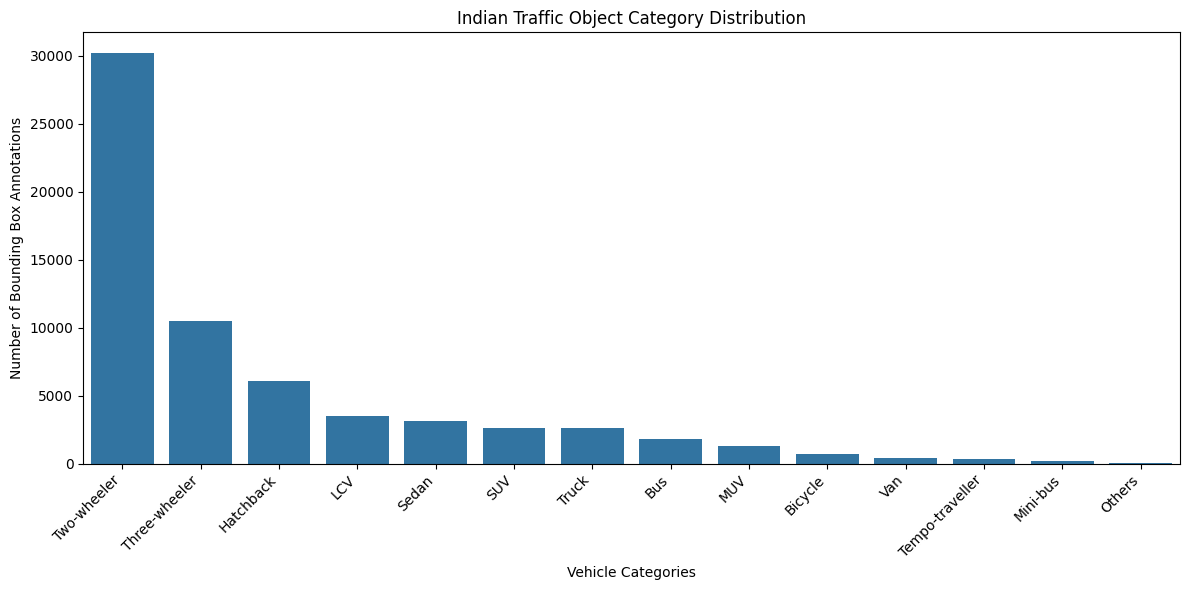

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

category_map = {
    cat["id"]: cat["name"]
    for cat in categories
}

category_counts = {}

for ann in annotations:
    name = category_map[ann["category_id"]]

    category_counts[name] = (
        category_counts.get(name, 0) + 1
    )

category_df = pd.DataFrame(
    list(category_counts.items()),
    columns=["Category", "Count"]
).sort_values("Count", ascending=False)

print(category_df)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_df,
    x="Category",
    y="Count"
)

plt.title("Indian Traffic Object Category Distribution")
plt.xlabel("Vehicle Categories")
plt.ylabel("Number of Bounding Box Annotations")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


In [ ]:
import random
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Select four images that contain annotations
annotated_image_ids = set(
    ann["image_id"] for ann in annotations
)

available_images = [
    img for img in images
    if img["id"] in annotated_image_ids
]

selected_images = random.sample(
    available_images,
    min(4, len(available_images))
)

image_folder = "/content/uvh26_samples"
os.makedirs(image_folder, exist_ok=True)

def download_traffic_image(image_info):

    filename = image_info["file_name"]

    # Match the image filename to its actual repository path
    matches = [
        f for f in repo_files
        if f.endswith("/" + filename.lstrip("/"))
        or f == filename.lstrip("/")
    ]

    if not matches:
        matches = [
            f for f in repo_files
            if os.path.basename(f) == os.path.basename(filename)
            and f.lower().endswith((".png", ".jpg", ".jpeg"))
        ]

    if not matches:
        raise FileNotFoundError(
            "Could not locate image: " + filename
        )

    remote_path = matches[0]

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        filename=remote_path,
        repo_type="dataset"
    )

    return local_path


print("Downloading sample images...")

for img in selected_images:
    img["local_path"] = download_traffic_image(img)

print("Sample images downloaded successfully!")


UVH-26-Val/data/000/496106.png: reconstructing file:   0%|          |  0.00B / 2.77MB            

UVH-26-Val/data/000/496106.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/940494.png: reconstructing file:   0%|          |  0.00B / 3.84MB            

UVH-26-Val/data/000/940494.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/824307.png: reconstructing file:   0%|          |  0.00B / 4.42MB            

UVH-26-Val/data/000/824307.png: downloading bytes:           |  0.00B            

UVH-26-Val/data/000/829240.png: reconstructing file:   0%|          |  0.00B / 4.38MB            

UVH-26-Val/data/000/829240.png: downloading bytes:           |  0.00B            

Sample images downloaded successfully!


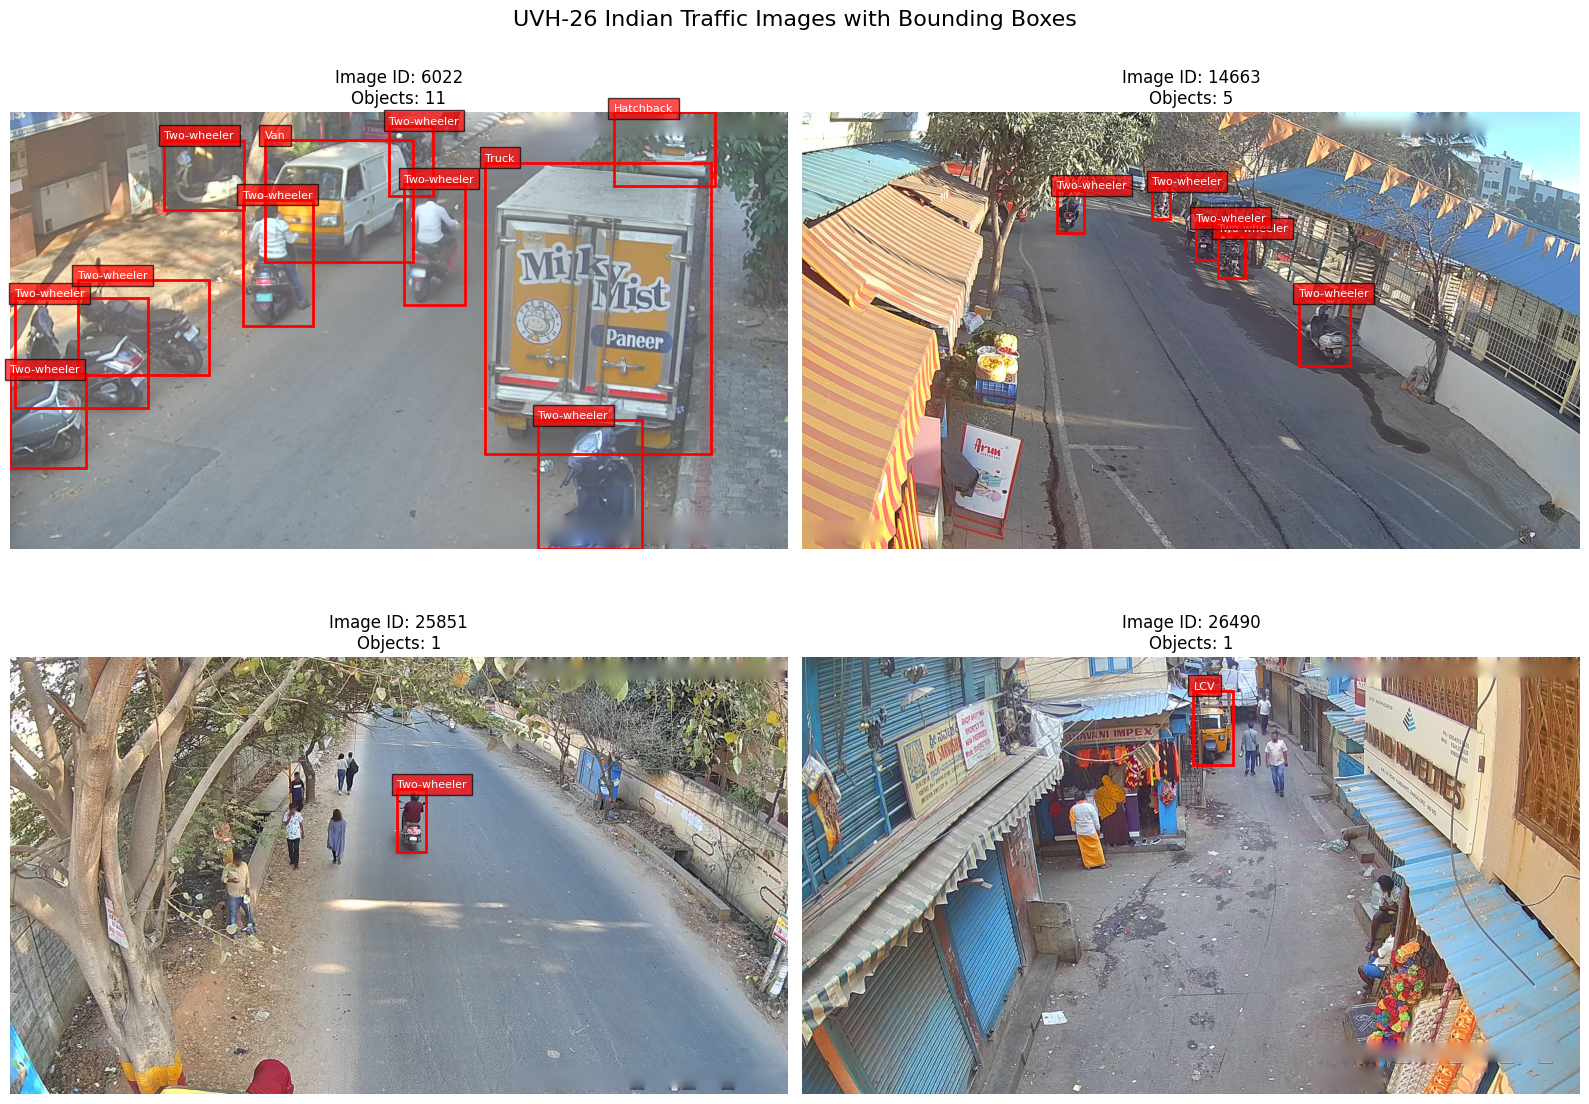

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for ax, img_info in zip(axes, selected_images):

    image = cv2.imread(img_info["local_path"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)

    # Find annotations belonging to this image
    image_annotations = [
        ann for ann in annotations
        if ann["image_id"] == img_info["id"]
    ]

    for ann in image_annotations:

        x, y, w, h = ann["bbox"]

        category_name = category_map[
            ann["category_id"]
        ]

        rectangle = patches.Rectangle(
            (x, y),
            w,
            h,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rectangle)

        ax.text(
            x,
            max(0, y - 5),
            category_name,
            color="white",
            fontsize=8,
            bbox=dict(facecolor="red", alpha=0.7)
        )

    ax.set_title(
        f"Image ID: {img_info['id']}\n"
        f"Objects: {len(image_annotations)}"
    )

    ax.axis("off")

plt.suptitle(
    "UVH-26 Indian Traffic Images with Bounding Boxes",
    fontsize=16
)

plt.tight_layout()
plt.show()